# Allele-specific methylation and sequence analysis

This is a big-picture look at the methylation and sequencing data and how they interact, investigating whether methylation follows the strain sequence or parent of origin (methylation -> sequence or parent of origin).

## Data overview

- **Methylation input:** `genetic_data/processed/methylation_cpg_counts_mm9.tsv.gz`, generated from the F1i (129 M, CAST P) and F1r (CAST M, 129 F) crosses. We stream it and take a deterministic 5% CpG sample to keep notebook memory use reasonable. The two complementary strand calls are combined at the CpG dyad by adding their methylated and unmethylated read counts.
- **Sequence input:** mm9 consensus FASTAs for CAST and 129S1/SvImJ. The latter is a proxy for the experiment's 129X1/SvJ strain, not the exact experimental strain. The notebook searches both `genetic_data/ref/` and `genetic_data/processed/ref/`.
- **Reciprocal-cross logic:** F1i has 129 maternal / CAST paternal; F1r has CAST maternal / 129 paternal. A strain-linked signal tends to keep the same sign for `129 - CAST` in both crosses. A parent-linked signal tends to reverse that sign when the parental strain assignment is reversed.
- These are pooled samples, not biological replicates. The plots and candidate ranks are exploratory; read counts are not biological replicates, so this notebook does not report inferential p-values. MethylC-seq also does not distinguish 5mC from 5hmC.

The sequence comparisons use mm9 coordinates and local 101 bp windows. They test association with observed sequence differences, not causality. A variant-proxied FASTA cannot substitute for the missing 129X1/SvJ sequence.


In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyfaidx import Fasta

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "font.size": 10,
})

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "genetic_data").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find genetic_data/. Open this notebook from the project "
        "directory or one of its subdirectories."
    )

ROOT = find_project_root()
METHYLATION_PATH = ROOT / "genetic_data/processed/methylation_cpg_counts_mm9.tsv.gz"

def first_existing(paths, description):
    for path in paths:
        if path.is_file():
            return path
    choices = "\n".join(f"  - {path}" for path in paths)
    raise FileNotFoundError(f"Could not find {description}. Checked:\n{choices}")

CAST_FASTA = first_existing(
    [
        ROOT / "genetic_data/processed/ref/mm9_CAST.fa",
        ROOT / "genetic_data/processed/ref/mm9_CAST_EiJ.fa",
        ROOT / "genetic_data/ref/mm9_CAST_EiJ.fa",
    ],
    "the CAST mm9 FASTA",
)
STRAIN129_FASTA = first_existing(
    [
        ROOT / "genetic_data/processed/ref/mm9_129.fa",
        ROOT / "genetic_data/processed/ref/mm9_129S1_SvImJ.fa",
        ROOT / "genetic_data/ref/mm9_129S1_SvImJ.fa",
    ],
    "the 129 mm9 FASTA",
)
if not METHYLATION_PATH.is_file():
    raise FileNotFoundError(f"Methylation table not found: {METHYLATION_PATH}")

print(f"Project:       {ROOT}")
print(f"Methylation:   {METHYLATION_PATH}")
print(f"CAST sequence: {CAST_FASTA}")
print(f"129 sequence:  {STRAIN129_FASTA}")


Project:       /home/html1101/projects/genai/ImprintMethyl
Methylation:   /home/html1101/projects/genai/ImprintMethyl/genetic_data/processed/methylation_cpg_counts_mm9.tsv.gz
CAST sequence: /home/html1101/projects/genai/ImprintMethyl/genetic_data/ref/mm9_CAST_EiJ.fa
129 sequence:  /home/html1101/projects/genai/ImprintMethyl/genetic_data/ref/mm9_129S1_SvImJ.fa


## 1. Read and prepare the methylation data

The source table stores one record per cross, strand, and CpG observation. For the Watson strand, the reported 1-based position is the CpG's cytosine; for Crick, the CpG cytosine is one base to the left. We convert both to the same CpG coordinate and add the two strand-specific read counts. Only autosomal CG sites with assigned 129 and CAST reads are included.

To keep the analysis reproducible without loading the multi-million-row table all at once, a coordinate-based hash selects the same 5% of CpGs in both crosses and on both strands. This is a deterministic subset—not a random split between train and test.


In [2]:
SAMPLE_PCT = 5
CHUNK_ROWS = 500_000
MIN_ALLELE_COVERAGE = 10
AUTOSOMES = {f"chr{i}" for i in range(1, 20)}

count_columns = [
    "129_methylated", "129_unmethylated",
    "Cast_methylated", "Cast_unmethylated",
]
read_columns = [
    "cross", "strand", "chrom", "pos_as_reported", "context", *count_columns,
]
partials = []
rows_read = 0
rows_in_sample = 0

for chunk in pd.read_csv(
    METHYLATION_PATH,
    sep="\t",
    compression="gzip",
    usecols=read_columns,
    chunksize=CHUNK_ROWS,
    dtype={
        "cross": "category",
        "strand": "category",
        "chrom": "category",
        "context": "category",
        "pos_as_reported": "int64",
        **{column: "int32" for column in count_columns},
    },
):
    rows_read += len(chunk)
    is_autosome = chunk["chrom"].astype(str).isin(AUTOSOMES)
    is_cpg = chunk["context"].astype(str).eq("CG")
    is_cross = chunk["cross"].astype(str).isin(["F1i", "F1r"])
    use = is_autosome & is_cpg & is_cross
    if not use.any():
        continue

    block = chunk.loc[use, ["cross", "strand", "chrom", "pos_as_reported", *count_columns]].copy()
    position = block["pos_as_reported"].to_numpy(dtype=np.int64)
    is_crick = block["strand"].astype(str).eq("crick").to_numpy()
    cpg_position = position - is_crick.astype(np.int64)
    chromosome_number = block["chrom"].astype(str).str[3:].to_numpy(dtype=np.uint64)
    coordinate_hash = (
        cpg_position.astype(np.uint64) * np.uint64(2_654_435_761)
        + chromosome_number * np.uint64(2_246_822_519)
    ) % np.uint64(100)
    sampled = coordinate_hash < SAMPLE_PCT
    if not sampled.any():
        continue

    block = block.loc[sampled].copy()
    block["cpg"] = cpg_position[sampled]
    rows_in_sample += len(block)
    partials.append(
        block.groupby(["cross", "chrom", "cpg"], observed=True, sort=False)[count_columns]
        .sum()
        .reset_index()
    )
    del chunk, block
    gc.collect()

if not partials:
    raise ValueError("No autosomal CpG observations were selected; check the input table.")

site_cross = (
    pd.concat(partials, ignore_index=True)
    .groupby(["cross", "chrom", "cpg"], observed=True, sort=False)[count_columns]
    .sum()
    .reset_index()
)
del partials
gc.collect()

print(f"Rows scanned: {rows_read:,}")
print(f"Strand observations in deterministic sample: {rows_in_sample:,}")
print(f"Unique CpG-by-cross records after merging strands: {len(site_cross):,}")
site_cross.head()


Rows scanned: 27,732,275
Strand observations in deterministic sample: 1,369,448
Unique CpG-by-cross records after merging strands: 913,230


,cross,chrom,cpg,129_methylated,129_unmethylated,Cast_methylated,Cast_unmethylated
0,F1i,chr1,3060721,49,12,40,13
1,F1i,chr1,3107021,0,0,17,5
2,F1i,chr1,3138221,0,0,11,1
3,F1i,chr1,3140103,2,1,28,4
4,F1i,chr1,3187444,6,10,12,17


## 2. Make reciprocal-cross, strain-level comparisons

For every selected CpG, we keep sites covered by both strains in **both** crosses. Methylation is computed as pooled methylated reads divided by pooled methylated plus unmethylated reads. The main effect sizes are differences in fractions, not significance tests.

- `delta_F1i = methylation(129) - methylation(CAST)` in F1i.
- `delta_F1r = methylation(129) - methylation(CAST)` in F1r.
- If the strain contrast is reproducible between crosses, these deltas tend to have the same sign.
- If methylation follows the parent instead, the strain contrast tends to switch sign because the maternal/paternal strain assignments are reversed.

These are diagnostic patterns, not definitive classifications: cross-wide technical differences and pooled samples can still confound them.


In [3]:
site_tables = []
for cross in ["F1i", "F1r"]:
    part = site_cross.loc[site_cross["cross"].astype(str).eq(cross)].copy()
    part["129_coverage"] = part["129_methylated"] + part["129_unmethylated"]
    part["CAST_coverage"] = part["Cast_methylated"] + part["Cast_unmethylated"]
    part["129_fraction"] = part["129_methylated"] / part["129_coverage"].replace(0, np.nan)
    part["CAST_fraction"] = part["Cast_methylated"] / part["CAST_coverage"].replace(0, np.nan)
    keep_columns = [
        "chrom", "cpg", "129_methylated", "129_unmethylated",
        "Cast_methylated", "Cast_unmethylated", "129_coverage",
        "CAST_coverage", "129_fraction", "CAST_fraction",
    ]
    part = part[keep_columns].rename(
        columns={column: f"{cross}_{column}" for column in keep_columns if column not in {"chrom", "cpg"}}
    )
    site_tables.append(part)

paired = site_tables[0].merge(site_tables[1], on=["chrom", "cpg"], how="inner", validate="one_to_one")
paired = paired.dropna(subset=["F1i_129_fraction", "F1i_CAST_fraction", "F1r_129_fraction", "F1r_CAST_fraction"])
paired = paired.loc[
    (paired["F1i_129_coverage"] >= MIN_ALLELE_COVERAGE)
    & (paired["F1i_CAST_coverage"] >= MIN_ALLELE_COVERAGE)
    & (paired["F1r_129_coverage"] >= MIN_ALLELE_COVERAGE)
    & (paired["F1r_CAST_coverage"] >= MIN_ALLELE_COVERAGE)
].copy()

paired["delta_F1i"] = paired["F1i_129_fraction"] - paired["F1i_CAST_fraction"]
paired["delta_F1r"] = paired["F1r_129_fraction"] - paired["F1r_CAST_fraction"]
paired["cis_effect"] = (paired["delta_F1i"] + paired["delta_F1r"]) / 2
paired["parent_effect_F1i"] = paired["delta_F1i"]
paired["parent_effect_F1r"] = -paired["delta_F1r"]
paired["delta_product"] = paired["delta_F1i"] * paired["delta_F1r"]
paired["pattern"] = np.select(
    [paired["delta_product"] > 0, paired["delta_product"] < 0],
    ["strain-concordant", "parent-concordant"],
    default="mixed / near-zero",
)

print(f"Matched CpGs with >= {MIN_ALLELE_COVERAGE} reads per strain in each cross: {len(paired):,}")
print(f"Retained {len(paired) / max(len(site_tables[0]), 1):.1%} of F1i sample CpGs after reciprocal matching and coverage filtering.")
display(paired["pattern"].value_counts().rename("CpG sites").to_frame())


Matched CpGs with >= 10 reads per strain in each cross: 197,996
Retained 43.5% of F1i sample CpGs after reciprocal matching and coverage filtering.


,CpG sites
pattern,
strain-concordant,102105
parent-concordant,75595
mixed / near-zero,20296


## 3. What do the methylation values look like?

This shows the distribution of methylation fractions for each strain in each reciprocal cross. A read-weighted fraction gives better-covered sites more precise estimates, but each CpG still contributes equally to these histograms.


,mean,std,min,max
F1i_129,0.696,0.084,0.000,0.975
F1i_CAST,0.702,0.081,0.236,0.936
F1r_129,0.713,0.078,0.091,1.000
F1r_CAST,0.718,0.076,0.315,1.000


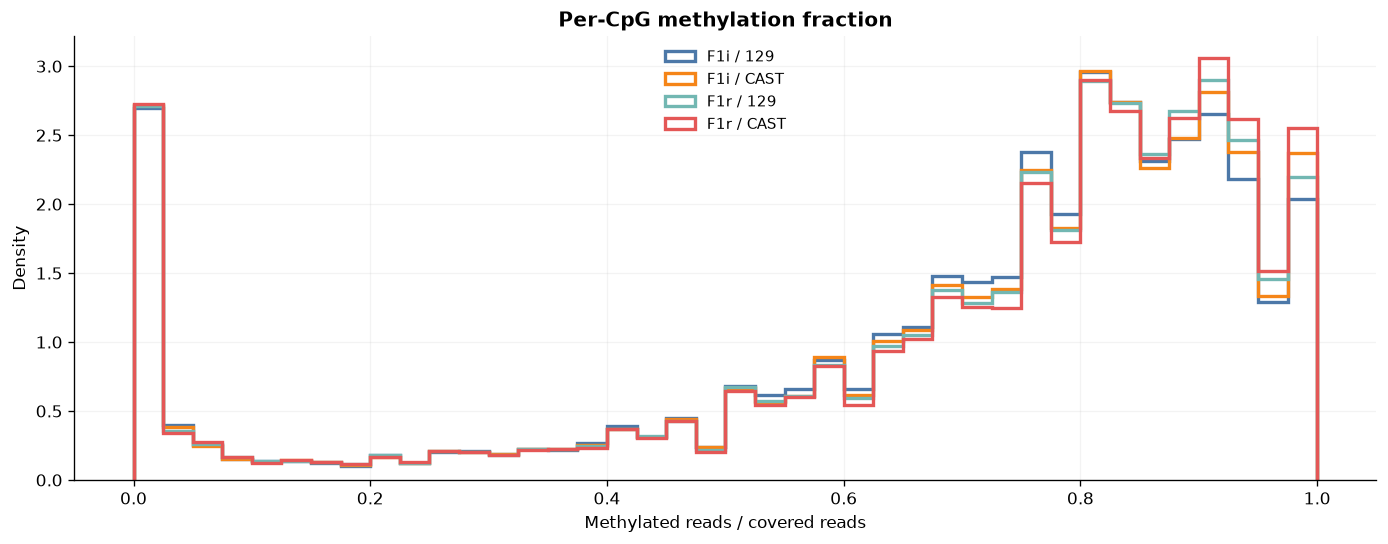

In [14]:
profile_columns = {
    "F1i_129_fraction": "F1i / 129",
    "F1i_CAST_fraction": "F1i / CAST",
    "F1r_129_fraction": "F1r / 129",
    "F1r_CAST_fraction": "F1r / CAST",
}

fig, axes = plt.subplots(1, 1, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.15]})
colors = ["#4C78A8", "#F58518", "#72B7B2", "#E45756"]
for (column, label), color in zip(profile_columns.items(), colors):
    axes.hist(
        paired[column], bins=np.linspace(0, 1, 41).tolist(), density=True,
        histtype="step", linewidth=2, label=label, color=color,
    )
axes.set(title="Per-CpG methylation fraction", xlabel="Methylated reads / covered reads", ylabel="Density")
axes.legend(frameon=False, fontsize=9)
axes.grid(alpha=0.15)

BIN_SIZE = 1_000_000
bin_counts = paired.assign(bin_start=(paired["cpg"] // BIN_SIZE) * BIN_SIZE)
bin_rows = []
for cross in ["F1i", "F1r"]:
    for strain, prefix in [("129", "129"), ("CAST", "CAST")]:
        met = f"{cross}_{prefix}_methylated" if prefix == "129" else f"{cross}_Cast_methylated"
        unm = f"{cross}_{prefix}_unmethylated" if prefix == "129" else f"{cross}_Cast_unmethylated"
        cov = f"{cross}_{prefix}_coverage"
        grouped = bin_counts.groupby(["chrom", "bin_start"], observed=True)[[met, unm]].sum()
        grouped[f"{cross}_{strain}"] = grouped[met] / (grouped[met] + grouped[unm])
        bin_rows.append(grouped[[f"{cross}_{strain}"]])
bin_profiles = pd.concat(bin_rows, axis=1).dropna()
display(bin_profiles.describe().T[["mean", "std", "min", "max"]].round(3))



## 4. Search for reciprocal-cross ASM patterns

The scatter plot compares the 129-minus-CAST methylation difference at the same CpG in F1i and F1r. Points in the same-sign quadrants are **strain-concordant** and are compatible with a cis/sequence-linked effect. Points in opposite-sign quadrants are **parent-concordant** and are compatible with parent-of-origin regulation. The thresholds used for the highlighted candidate list are deliberately explicit and adjustable below; they are effect-size filters, not statistical significance.


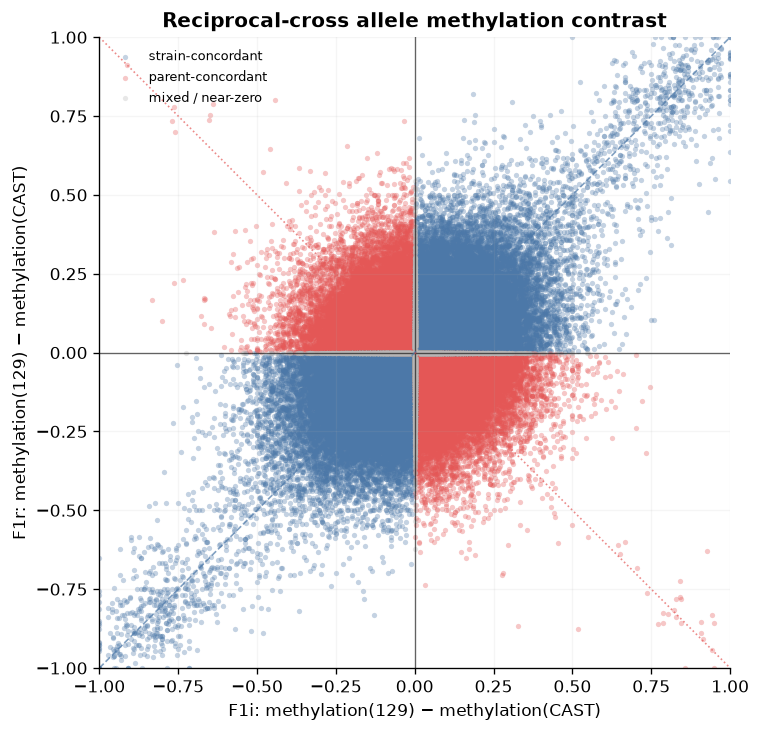

Pearson correlation of reciprocal 129−CAST contrasts: 0.363


,Percent of matched CpGs
pattern,
strain-concordant,51.6
parent-concordant,38.2
mixed / near-zero,10.3


Exploratory strong cis-pattern candidates (|delta| >= 0.2 in both crosses, same sign): 6,705


,chrom,cpg,F1i_129_fraction,F1i_CAST_fraction,F1r_129_fraction,F1r_CAST_fraction,delta_F1i,delta_F1r,F1i_129_coverage,F1i_CAST_coverage,F1r_129_coverage,F1r_CAST_coverage,mean_abs_delta
407255,chr6,50643108,0.000,1.000,0.000,1.000,-1.000,-1.000,39,13,25,25,1.000
37463,chr10,109507192,1.000,0.000,1.000,0.000,1.000,1.000,13,16,18,13,1.000
341105,chr11,26428413,1.000,0.000,1.000,0.000,1.000,1.000,19,17,28,29,1.000
402583,chr5,110637128,0.000,1.000,0.000,1.000,-1.000,-1.000,24,23,18,18,1.000
205589,chr3,139495263,0.000,1.000,0.000,1.000,-1.000,-1.000,22,35,16,23,1.000
204069,chr3,129718904,0.000,1.000,0.000,1.000,-1.000,-1.000,60,30,34,26,1.000
93577,chr14,16073535,1.000,0.000,1.000,0.000,1.000,1.000,22,10,16,13,1.000
158436,chr19,4834081,0.963,0.000,1.000,0.000,0.963,1.000,27,17,18,17,0.981
250421,chr5,143563187,0.955,0.000,1.000,0.000,0.955,1.000,22,19,19,25,0.977
415124,chr7,115923870,1.000,0.000,0.955,0.000,1.000,0.955,20,13,22,14,0.977


In [5]:
MIN_ABS_DELTA = 0.20
paired["strong_cis_candidate"] = (
    (paired["delta_F1i"].abs() >= MIN_ABS_DELTA)
    & (paired["delta_F1r"].abs() >= MIN_ABS_DELTA)
    & (paired["delta_product"] > 0)
)
paired["strong_parent_pattern"] = (
    (paired["delta_F1i"].abs() >= MIN_ABS_DELTA)
    & (paired["delta_F1r"].abs() >= MIN_ABS_DELTA)
    & (paired["delta_product"] < 0)
)

fig, ax = plt.subplots(figsize=(7.2, 6.2))
for pattern, color in [
    ("strain-concordant", "#4C78A8"),
    ("parent-concordant", "#E45756"),
    ("mixed / near-zero", "#B8B8B8"),
]:
    subset = paired.loc[paired["pattern"].eq(pattern)]
    ax.scatter(subset["delta_F1i"], subset["delta_F1r"], s=10, alpha=0.33, label=pattern, color=color, linewidths=0)
ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)
ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
ax.axline((0, 0), slope=1, color="#4C78A8", linestyle="--", linewidth=1, alpha=0.7)
ax.axline((0, 0), slope=-1, color="#E45756", linestyle=":", linewidth=1, alpha=0.7)
ax.set(
    title="Reciprocal-cross allele methylation contrast",
    xlabel="F1i: methylation(129) - methylation(CAST)",
    ylabel="F1r: methylation(129) - methylation(CAST)",
    xlim=(-1, 1), ylim=(-1, 1),
)
ax.set_aspect("equal", adjustable="box")
ax.legend(frameon=False, loc="upper left", fontsize=8)
ax.grid(alpha=0.12)
plt.tight_layout()
plt.show()

pattern_fraction = paired["pattern"].value_counts(normalize=True).reindex(
    ["strain-concordant", "parent-concordant", "mixed / near-zero"], fill_value=0
)
print(f"Pearson correlation of reciprocal 129-CAST contrasts: {np.corrcoef(paired['delta_F1i'], paired['delta_F1r'])[0, 1]:.3f}")
display((100 * pattern_fraction).rename("Percent of matched CpGs").to_frame().round(1))

candidate_columns = [
    "chrom", "cpg", "F1i_129_fraction", "F1i_CAST_fraction",
    "F1r_129_fraction", "F1r_CAST_fraction", "delta_F1i", "delta_F1r",
    "F1i_129_coverage", "F1i_CAST_coverage", "F1r_129_coverage", "F1r_CAST_coverage",
]
cis_candidates = paired.loc[paired["strong_cis_candidate"], candidate_columns].copy()
cis_candidates["mean_abs_delta"] = (cis_candidates["delta_F1i"].abs() + cis_candidates["delta_F1r"].abs()) / 2
print(f"Exploratory strong cis-pattern candidates (|delta| >= {MIN_ABS_DELTA} in both crosses, same sign): {len(cis_candidates):,}")
display(cis_candidates.sort_values("mean_abs_delta", ascending=False).head(20).round(3))


## 6. Do local sequence differences track the strain-consistent effects?

We compare 101 bp windows around a reproducible random sample of eligible CpGs, plus the strongest reciprocal cis-pattern candidates for inspection. The local mismatch count is a simple sequence feature. The mismatch-versus-effect plot uses only the random sample; the extra candidate windows are not included in that population-level descriptive comparison. A CpG can be methylated differently for many reasons, so an association between sequence mismatch and methylation contrast is only a candidate sequence-dependent ASM signal.

The FASTAs can be several gigabytes. `pyfaidx` provides indexed random access and creates a `.fai` index alongside each FASTA the first time it is opened. Indexing reads the FASTA once; subsequent notebook runs reuse the index.


In [8]:
SEQUENCE_WINDOW = 101
SEQUENCE_BACKGROUND_N = 5000
SEQUENCE_TOP_N = 500

background_sites = paired.sample(n=min(SEQUENCE_BACKGROUND_N, len(paired)), random_state=23).copy()
background_sites["sequence_selection"] = "representative random sample"
candidate_pool = paired.loc[paired["strong_cis_candidate"]].copy()
candidate_pool["cis_effect_size"] = (candidate_pool["delta_F1i"].abs() + candidate_pool["delta_F1r"].abs()) / 2
top_sequence_sites = candidate_pool.nlargest(min(SEQUENCE_TOP_N, len(candidate_pool)), "cis_effect_size").copy()
top_sequence_sites["sequence_selection"] = "top reciprocal cis candidates"
sequence_sites = pd.concat([background_sites, top_sequence_sites], ignore_index=True)
sequence_sites = sequence_sites.drop_duplicates(["chrom", "cpg"], keep="last").copy()
sequence_sites["cis_effect_size"] = (sequence_sites["delta_F1i"].abs() + sequence_sites["delta_F1r"].abs()) / 2
sequence_sites["effect_group"] = np.where(
    sequence_sites["strong_cis_candidate"], "strong reciprocal cis pattern", "background / other"
)

fasta_129 = Fasta(str(STRAIN129_FASTA), as_raw=True, sequence_always_upper=True)
fasta_cast = Fasta(str(CAST_FASTA), as_raw=True, sequence_always_upper=True)
print("Indexed FASTA lengths on chr1:")
print("129:", len(fasta_129["chr1"]), "CAST:", len(fasta_cast["chr1"]))

half_window = SEQUENCE_WINDOW // 2
sequence_results = []
for row in sequence_sites[["chrom", "cpg", "delta_F1i", "delta_F1r", "cis_effect_size", "effect_group", "sequence_selection"]].itertuples(index=False):
    chrom, cpg, delta_f1i, delta_f1r, effect_size, effect_group, sequence_selection = row
    center0 = int(cpg) - 1
    start = max(0, center0 - half_window)
    end = center0 + half_window + 1
    try:
        seq_129 = str(fasta_129[str(chrom)][start:end]).upper()
        seq_cast = str(fasta_cast[str(chrom)][start:end]).upper()
    except KeyError:
        continue
    if len(seq_129) != SEQUENCE_WINDOW or len(seq_cast) != SEQUENCE_WINDOW:
        continue
    if "N" in seq_129 or "N" in seq_cast:
        continue
    mismatch_count = sum(base_129 != base_cast for base_129, base_cast in zip(seq_129, seq_cast))
    center = half_window
    sequence_results.append(
        {
            "chrom": chrom,
            "cpg": int(cpg),
            "delta_F1i": delta_f1i,
            "delta_F1r": delta_f1r,
            "cis_effect_size": effect_size,
            "effect_group": effect_group,
            "sequence_selection": sequence_selection,
            "mismatch_bp_101": mismatch_count,
            "129_has_CG": seq_129[center:center + 2] == "CG",
            "CAST_has_CG": seq_cast[center:center + 2] == "CG",
            "sequence_129": seq_129,
            "sequence_CAST": seq_cast,
        }
    )
sequence_features = pd.DataFrame(sequence_results)
print(f"Windows compared: {len(sequence_features):,} of {len(sequence_sites):,} selected CpGs")
display(sequence_features[["mismatch_bp_101", "129_has_CG", "CAST_has_CG", "cis_effect_size"]].describe().round(3))


Indexed FASTA lengths on chr1:
129: 197195432 CAST: 197195432
Windows compared: 5,493 of 5,494 selected CpGs


,mismatch_bp_101,cis_effect_size
count,5493.000,5493.000
mean,1.820,0.171
std,1.402,0.234
min,0.000,0.000
25%,1.000,0.051
50%,1.000,0.093
75%,2.000,0.158
max,12.000,1.000


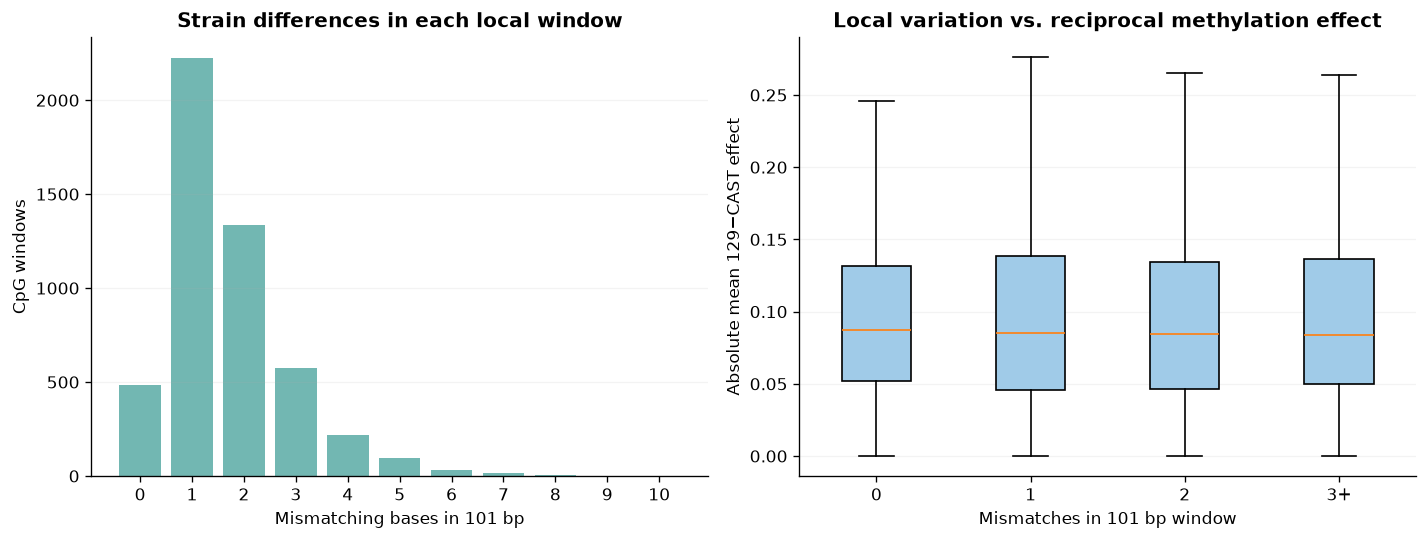

Windows with >=1 129-vs-CAST mismatch in the random sample: 90.3%
Median |mean reciprocal allele effect|:


,cis_effect_size
mismatch_bp_101,
no local mismatch,0.087
one or more mismatches,0.085


CpG motif preserved in each strain FASTA:


,fraction
129_has_CG,0.996
CAST_has_CG,0.998


Top candidate windows (sequence comparison is for follow-up, not a significance ranking):


,chrom,cpg,delta_F1i,delta_F1r,mismatch_bp_101,129_has_CG,CAST_has_CG,sequence_129,sequence_CAST
5233,chr6,74569967,-0.833333,-0.892857,12,False,True,GAACTTGGAGATTTGCAGTGCGCTTTGATATCAGATATGGCGATGC...,GGAATTGGAAATTTGCAGTGTGCTTTGATGTCAAACATGGAGATGC...
5064,chr2,58801542,0.886364,0.976744,10,True,False,CTGACACCCTTCCCAGCCCTTCCTGTAAAAGCCAAGCATTGATTAC...,CTGCCACCCTTCCCAGCCCTTCCTGTAAGAGCCAAGTATTGATTAC...
5095,chr3,133451463,0.909091,0.920000,10,True,False,AACTCACTGCATATATCCATTACAACATTAGTTCTTATACCTCCGA...,AACTCACTGCATATATCCATTACAATATGAGTTTTTATACCTCCAA...
5142,chr8,40541132,-0.958333,-0.823529,10,False,True,ACATGCGGATTAAATATTAAAATATGGCCTCCGCTCTCACCCCTTC...,ACATGCGGATTAAATATTAAAATATGGCCTCCACTCTCACTCCTTC...
5193,chr18,81710619,0.786078,0.966667,10,True,False,ACCAGCCGTGTCCATACACTCAGCTTCCTGGAAATCGCCTGTCTGT...,ACCAGCTGTGTCCACACACTCAGCTTCCTATAAATCACCTGTCTGC...
5180,chr12,4707916,0.866667,0.893617,10,True,False,TCCAAGGGTCCTAGATCACTCACACCCCGGAAGCCATGGCTCATTC...,TCCAAGGCTCCTAGATCTCTCACACCCCAGAAGCCATGGCTCGTGC...
5285,chr9,104696171,0.833333,0.861111,10,True,False,AGCTAGTCTTCCCCAGGGAAGAGCACCCCAATCTGTTATACGATAC...,AGCTAGTCTTCCCCAGGGAAGAGCACATGAATCTGTTATAGGATAT...
5081,chr7,48613111,0.926829,0.920000,9,True,False,AGGAAAAACGCAACATGGTCGGATTCTTCTCAACAGCTTTATTCTT...,AGGAAAAACGCAACATGGTCAGATTCTTGTCAACAGCTTTATTCCT...
5308,chr15,54831838,0.854545,0.826580,9,True,False,CCACGTTGATATGCAAGGGCTGTGCAGACTTGGTCCCATCTCTCAC...,CCACGTTGATATGCAAGGGCTGTGCAGACTTGTTCCCATTTCTCAT...
5200,chr9,105646889,0.823529,0.924242,9,True,False,ACAAAATACAATACAGTGTCACTCCATTCTCTATTGTGCCCTCTGC...,ACAAAATACAATACAGTGTCACTCCATTCTCTATTGTGTCCTCTGC...


In [9]:
if sequence_features.empty:
    print("No complete sequence windows were available; check FASTA paths and chromosome names.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    random_features = sequence_features.loc[sequence_features["sequence_selection"].eq("representative random sample")]
    mismatch_counts = random_features["mismatch_bp_101"].value_counts().sort_index()
    axes[0].bar(mismatch_counts.index.astype(str), mismatch_counts.values, color="#72B7B2")
    axes[0].set(title="Strain differences in each local window", xlabel="Mismatching bases in 101 bp", ylabel="CpG windows")
    axes[0].grid(axis="y", alpha=0.15)

    grouped = [
        random_features.loc[random_features["mismatch_bp_101"].eq(value), "cis_effect_size"].to_numpy()
        for value in [0, 1, 2, 3]
    ]
    labels = ["0", "1", "2", "3+"]
    grouped[3] = random_features.loc[random_features["mismatch_bp_101"].ge(3), "cis_effect_size"].to_numpy()
    axes[1].boxplot(grouped, tick_labels=labels, showfliers=False, patch_artist=True, boxprops={"facecolor": "#A0CBE8"})
    axes[1].set(title="Local variation vs. reciprocal methylation effect", xlabel="Mismatches in 101 bp window", ylabel="Absolute mean 129−CAST effect")
    axes[1].grid(axis="y", alpha=0.15)
    fig.tight_layout()
    plt.show()

    has_variant = random_features["mismatch_bp_101"].gt(0)
    print(f"Windows with >=1 129-vs-CAST mismatch in the random sample: {has_variant.mean():.1%}")
    print("Median |mean reciprocal allele effect|:")
    display(random_features.groupby(has_variant, observed=True)["cis_effect_size"].median().rename(index={False: "no local mismatch", True: "one or more mismatches"}).to_frame().round(3))
    print("CpG motif preserved in each strain FASTA:")
    display(random_features[["129_has_CG", "CAST_has_CG"]].mean().rename("fraction").to_frame().round(3))
    print("Top candidate windows (sequence comparison is for follow-up, not a significance ranking):")
    display(sequence_features.loc[sequence_features["sequence_selection"].eq("top reciprocal cis candidates"), ["chrom", "cpg", "delta_F1i", "delta_F1r", "mismatch_bp_101", "129_has_CG", "CAST_has_CG", "sequence_129", "sequence_CAST"]].sort_values("mismatch_bp_101", ascending=False).head(20))


## Interpretation guide and next steps

1. **Start with the reciprocal contrast.** Same-sign `129 - CAST` differences across F1i/F1r are more compatible with strain-linked cis differences; opposite signs are more compatible with parent-of-origin effects. Do not call either set definitive from these pooled data.
2. **Inspect local sequence.** The mismatch plot checks whether the 101 bp windows even differ between the available strain FASTAs. It is descriptive: a mismatch count ignores variant function, haplotype uncertainty, and long-range regulatory context.
3. **Treat PCA as a visualization.** Four profiles cannot support a replicated PCA or formal test. Regional patterning is useful for spotting broad similarities and differences only.
4. **Validate candidates.** Check high-effect sites in genomic context, coverage, known DMR annotations, mapping ambiguity, and independent biological samples. The 129 sequence is a proxy (129S1/SvImJ), so candidate effects involving 129 should be confirmed with the actual 129X1/SvJ haplotype.
5. **For a predictive model**, evaluate on held-out chromosomes or loci, not random CpGs. Nearby sites are correlated, and a model needs both the exact strain sequence and a defensible held-out split.

In the current 5% deterministic sample, the 129−CAST contrasts are moderately correlated between reciprocal crosses, but both same-strain and opposite-strain patterns occur. The random local-window sample also compares the effect-size distributions with and without nearby sequence mismatches. If those distributions are similar, mismatch count alone is not explaining the methylation contrast; this does **not** rule out effects from particular variants, motifs, CpG-disrupting substitutions, or sequence beyond the 101 bp window.

The notebook deliberately avoids p-values: read-level counts in pooled crosses do not provide biological replication. It also excludes non-CG contexts, unassigned reads, sex chromosomes, and lambda spike-in contigs from these autosomal CpG comparisons.
